In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('cumulative_fig_values.csv')
df

,model,panel,t_days,N,N_lo16,N_hi84,sqrt_N
0,naive_physical,Population,0.000000,0.000000,0.000000,0.000000e+00,0.000000
1,naive_physical,Population,36.893939,19963.708123,12252.890079,3.267517e+04,141.292987
2,naive_physical,Population,73.787879,40599.368386,24918.196311,6.645014e+04,201.492849
3,naive_physical,Population,110.681818,61331.452274,37642.683337,1.003829e+05,247.651877
4,naive_physical,Population,147.575758,81990.214030,50322.168301,1.341957e+05,286.339334
...,...,...,...,...,...,...,...
895,fe_dependent_physical,Oracle,3504.924242,758966.070483,467877.230597,1.247703e+06,871.186588
896,fe_dependent_physical,Oracle,3541.818182,766955.187014,472802.254076,1.260837e+06,875.759777
897,fe_dependent_physical,Oracle,3578.712121,774944.303546,477727.277556,1.273970e+06,880.309209
898,fe_dependent_physical,Oracle,3615.606061,782933.420077,482652.301036,1.287104e+06,884.835250


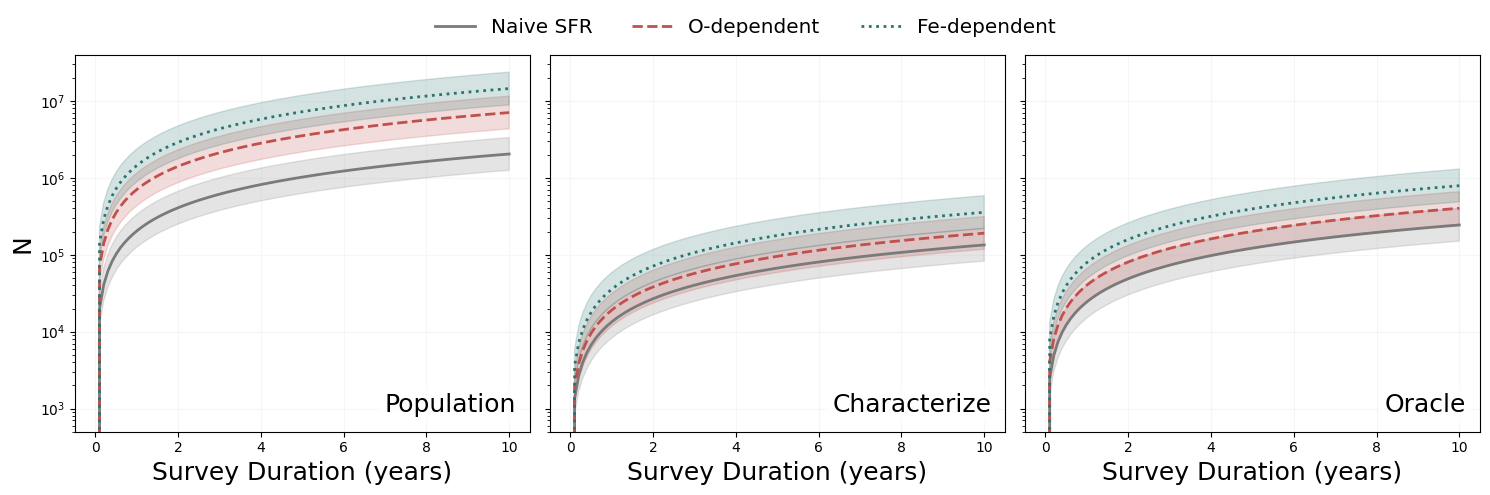

In [3]:
labels = {'naive_physical': 'Naive SFR', 'o_dependent_physical': 'O-dependent', 'fe_dependent_physical': 'Fe-dependent'}
colors = {'naive_physical': '#7a7a7a', 'o_dependent_physical': '#c0504d', 'fe_dependent_physical': '#2a7470'}
linestyles = {'naive_physical': '-', 'o_dependent_physical': '--', 'fe_dependent_physical': ':'}

panels = df['panel'].unique()
fig, axes = plt.subplots(1, len(panels), figsize=(15, 5), sharey=True)

for ax, panel in zip(axes, panels):
    for model in labels:
        d = df[(df['model'] == model) & (df['panel'] == panel)].sort_values('t_days')
        t_yr = d['t_days'] / 365.25
        ax.plot(t_yr, d['N'], label=labels[model], color=colors[model], ls=linestyles[model], lw=2)
        band_lo = d['N'] - np.hypot(d['N'] - d['N_lo16'], d['sqrt_N'])
        band_hi = d['N'] + np.hypot(d['N_hi84'] - d['N'], d['sqrt_N'])
        ax.fill_between(t_yr, band_lo, band_hi, color=colors[model], alpha=0.2)

    ax.text(0.97, 0.04, panel, transform=ax.transAxes, ha='right', va='bottom',
            fontsize=18, bbox=dict(facecolor='white', edgecolor='none', alpha=0.8))
    ax.set_xlabel('Survey Duration (years)', fontsize=18)
    ax.set_yscale('log')
    ax.grid(alpha=0.1)
axes[0].set_ylabel('N', fontsize=18)

handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc='upper center', ncol=len(handles),
           fontsize='x-large', frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.savefig('cumulative_fig.pdf', dpi=300, bbox_inches='tight')